# 08 · MLP view transform (negative control) → triplane (TPV), step by step

**`TRIPLANE_LIFTERS["mlp_view"]` → `lifting.triplane.MLPViewTriplaneLifter`**  ·  Pan et al., *View Parsing Network* (RA-L 2020) - geometry-free baseline

> One fully connected layer per (camera, plane) maps the image cells straight to plane cells; calibration is ignored - the control that proves every other triplane lifter really uses the cameras.

This notebook shows, cell by cell, how the **MLP view transform (negative control)** lifting technique produces a
**tri-perspective view** (three orthogonal feature planes `xy` = BEV, `xz`, `yz`) instead of a single
bird's-eye-view map, *without changing a line of the existing BEV lifter* - the triplane module wraps it
(composition) and only adds what is needed to keep the height axis.

| § | what you will see |
|---|---|
| 1 | the idea, the animated step-by-step GIF and a detailed Mermaid diagram |
| 2 | every animation step as a still image |
| 3 | the shared toy scene (4 cameras, vehicles, pedestrians) |
| 4 | building the triplane lifter from the registry |
| 5 | **inside the lifter**: every intermediate tensor, with exact checks |
| 6 | the triplane contract, verified |
| 7 | end-to-end training on 3D semantic occupancy |
| 8 | the negative control: does it really use the cameras? |
| 9 | how to use it in your own code, recap, cheat sheet, exercises |

## 1. The idea

![MLP view transform (negative control) triplane lifting animation](../../assets/triplane/mlp_view.gif)


VPN-style view parsing learns the image → plane mapping **from data alone**: for every camera and every plane, a
`Linear(h·w → H_P·W_P)` maps the flattened image cells to the plane cells (channels are shared), and cameras are
summed. There is no projection, no depth, no anchor - `uses_geometry = False`.

This is valuable as a **negative control**. In this repo's synthetic world every scene has a randomly rotated rig, so
"pixel (u, v) of camera 0" points in a different direction in every scene; a mapping that ignores the extrinsics
cannot localise objects. A triplane lifter that does *not* clearly beat this one is not using geometry. And since it
ignores the cameras, corrupting the extrinsics changes nothing (checked exactly in §5.2).

### Detailed diagram

Colours: <span style="color:#d48806">■ data</span> · <span style="color:#1f77b4">■ fixed geometry</span>
· <span style="color:#8e44ad">■ learned</span> · <span style="color:#2e8b57">■ reused from the existing BEV lifter</span>
· <span style="color:#c0392b">■ outputs</span>. (Mermaid renders in JupyterLab ≥ 4.1, VS Code and on GitHub;
the matplotlib version below renders everywhere.)

```mermaid
flowchart LR
  IMG["N camera images<br/>(B, N, 3, H, W)"]:::data --> ENC["ImageEncoder<br/>pyramid (B, N, C, H_l, W_l)"]:::learned
  CAM["Cameras<br/>K (B,N,3,3) · cam_to_ego (B,N,4,4)"]:::data
  subgraph VPN["MLPViewTriplaneLifter (new) · geometry-free"]
    direction TB
    FL["flatten each camera's h×w cells"]:::geo
    FL --> M1["Linear(h·w → X·Y) per camera"]:::learned
    FL --> M2["Linear(h·w → X·Z) per camera"]:::learned
    FL --> M3["Linear(h·w → Y·Z) per camera"]:::learned
    M1 & M2 & M3 --> SUM["sum over cameras<br/>+ ConvNormAct per plane"]:::learned
  end
  ENC --> FL
  CAM -. "ignored (uses_geometry = False)" .-> VPN
  SUM --> TPV
  TPV["TPVPlanes<br/>xy (B,C,X,Y) · xz (B,C,X,Z) · yz (B,C,Y,Z)"]:::out
  TPV --> BEVH["TriplaneBEVHead<br/>f = xy + xz + yz → fold Z<br/>BEV (B, C, X, Y)"]:::learned
  TPV --> AGG["TPVAggregator<br/>voxel logits (B,K,X,Y,Z)<br/>+ point logits (B,K,P)"]:::learned
  classDef data fill:#fff7e6,stroke:#d48806,color:#222
  classDef geo fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef learned fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef reused fill:#eaf7ea,stroke:#2e8b57,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

### Shapes and equations


$$ P_{c}[\,i\,] = \sum_{n=1}^{N} \sum_{j=1}^{h w} W^{(P,n)}_{i j}\, F_{n, c}[\,j\,] + b^{(P,n)}_i, \qquad
P \in \{xy, xz, yz\},\ i \in \text{cells of } P $$

followed by `ConvNormAct + 1×1 conv` per plane.

| tensor | shape |
|---|---|
| features (coarsest level) | `(B, N, C, h, w)` |
| view MLP per (plane, camera) | `Linear(h·w, H_P·W_P)` |
| planes | `xy (B,C,X,Y)`, `xz (B,C,X,Z)`, `yz (B,C,Y,Z)` |

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")

# tpv_kit lives next to this notebook; also works when Jupyter starts at the repo root.
for _p in (".", os.path.join("notebooks", "triplane")):
    if os.path.isdir(os.path.join(_p, "tpv_kit")):
        sys.path.insert(0, os.path.abspath(_p)); break

import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

from lifting import BaseLifter
from lifting.encoders import SimpleConvEncoder
from lifting.lifters import LIFTERS
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_lifter, build_triplane_model, build_triplane_bev_model
from tpv_kit import (TriplaneScene, PlanePlotter, PipelineDiagram, StoryboardViewer,
                     TriplaneContractChecker, OccupancyExperiment, ExperimentResult)

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 100, "image.interpolation": "nearest"})
plotter = PlanePlotter()
print("torch", torch.__version__, "| triplane lifters:", TRIPLANE_LIFTERS.names())

torch 2.14.1 | triplane lifters: ['alpamayo', 'bev_adapter', 'bevformer', 'depth_warp', 'lift_splat', 'mlp_view', 'simple_bev', 'tiim', 'tpvformer']


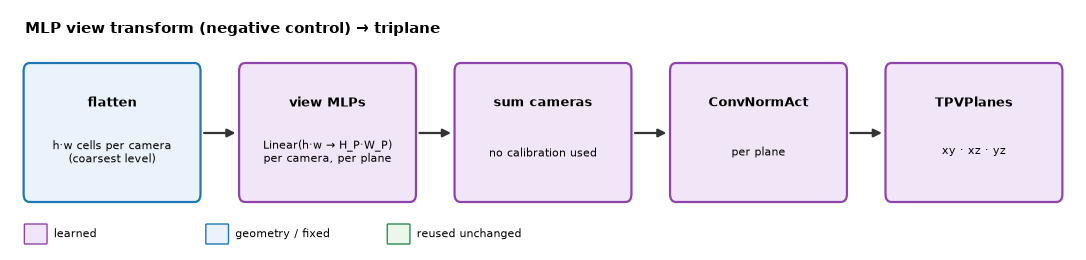

In [2]:
PipelineDiagram('MLP view transform (negative control) → triplane').extend([
    ('flatten', 'h·w cells per camera\n(coarsest level)', 'geometry'),
    ('view MLPs', 'Linear(h·w → H_P·W_P)\nper camera, per plane', 'learned'),
    ('sum cameras', 'no calibration used', 'learned'),
    ('ConvNormAct', 'per plane', 'learned'),
    ('TPVPlanes', 'xy · xz · yz', 'learned'),
]).show()

## 2. The animation, one still per step

The GIF above is rendered by `lifting.triplane.animation` (Pillow only, exact geometry on a toy scene:
4 cameras at the origin, a car, a pedestrian and a pole). `StoryboardViewer` re-renders the **final frame of every
step** so the whole sequence can be read at once. Regenerate all GIFs with `python scripts/make_triplane_gifs.py`.

step 1: Inputs
step 2: Flatten coarse feature cells
step 3: Per-camera, per-plane MLP
step 4: Sum over cameras -> planes
step 5: Rotate the rig: it cannot follow


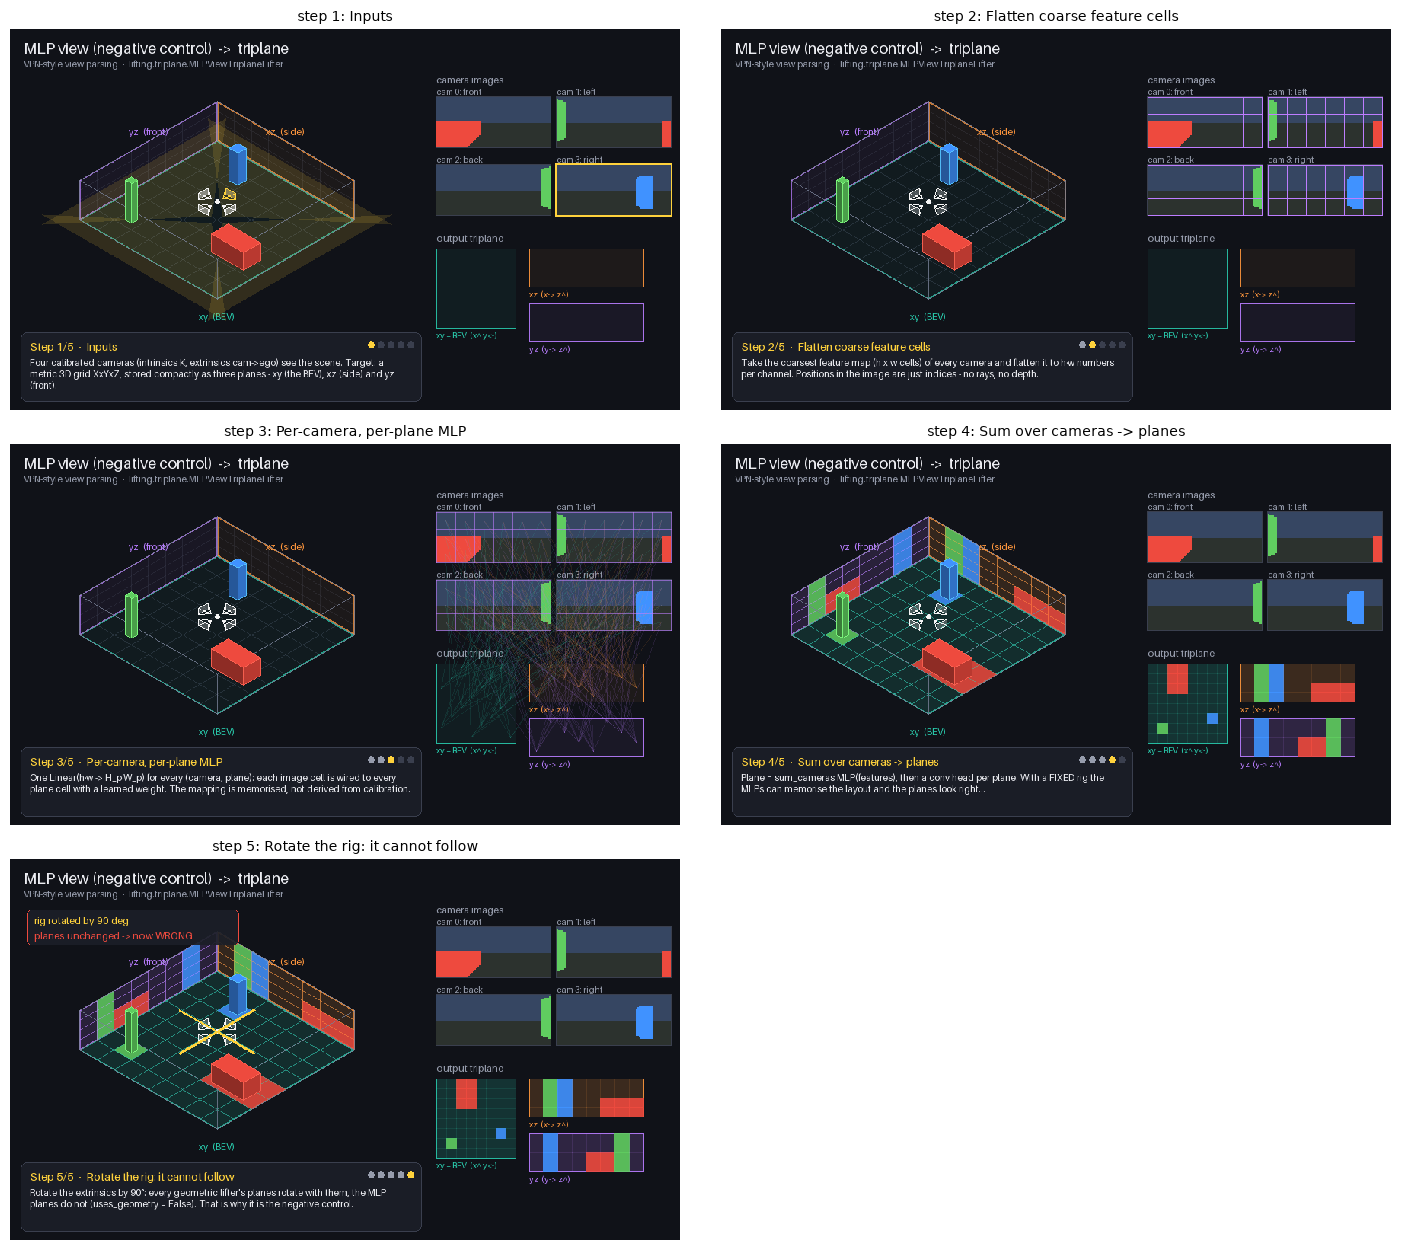

In [3]:
viewer = StoryboardViewer("mlp_view")
for i, title in enumerate(viewer.step_titles(), 1):
    print(f"step {i}: {title}")
viewer.contact_sheet()

## 3. The scene

Every triplane notebook uses the same `TriplaneScene`: a `32 m × 32 m × 4 m` region cut into `16 × 16 × 4`
cells, four `48 × 96` cameras whose yaw is **randomly rotated per scene** (so no network can memorise where
"front" is - it must read the calibration), and procedurally placed vehicles (red) and pedestrians (blue).
The ground truth is a 3D occupancy grid `(B, X, Y, Z)`; collapsing it along each axis gives the three
**label planes** each triplane is supervised against.

grid      : x (-16.0, 16.0) y (-16.0, 16.0) z (-1.0, 3.0) m, resolution (16, 16, 4)
voxel     : (2.0, 2.0, 1.0) m
cameras   : 4 x (48, 96) px
scenes    : 128 train / 32 test (batch 4)
TPV cells : xy 256 + xz 64 + yz 64 = 384  (voxels: 1024)


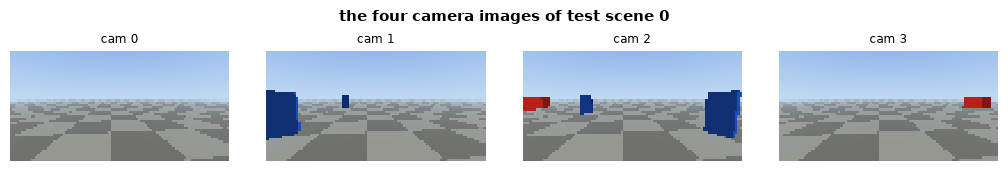

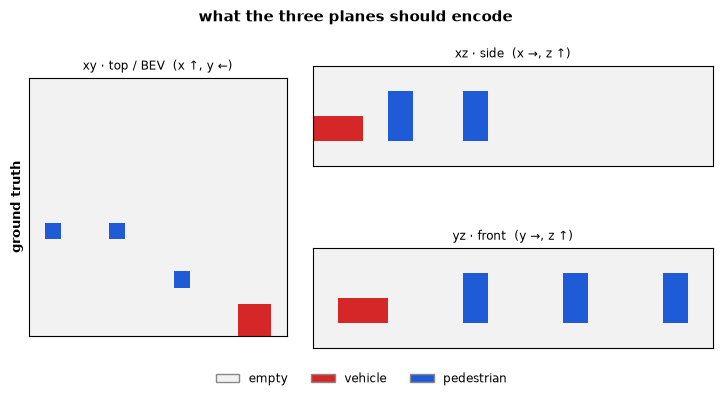

In [4]:
scene = TriplaneScene()
print(scene.describe())
batch = scene.sample
plotter.cameras(batch.images, title="the four camera images of test scene 0")
plotter.labels([("ground truth", scene.label_planes(batch.occupancy))], title="what the three planes should encode")

## 4. Build the triplane lifter

Two equivalent ways:

* `TRIPLANE_LIFTERS.build("mlp_view", grid=..., in_channels=..., out_channels=...)` - the raw registry;
* `build_triplane_lifter("mlp_view", grid, channels, image_size, num_cameras, encoder)` - also injects the
  context some lifters need (`feature_size`, `num_cameras`, `depth_bins`), exactly like `lifting.models.build_lifter`
  does for BEV lifters.

The image encoder turns `(B·N, 3, H, W)` images into a feature pyramid (strides 4 and 8 here); every lifter
consumes `(B, N, C, H_l, W_l)` per level.

In [5]:
C = 32
encoder = SimpleConvEncoder(out_channels=C, num_levels=2)
features = scene.encode(encoder, batch)
cameras = batch.cameras
print("feature pyramid:", [tuple(f.shape) for f in features])

lifter = build_triplane_lifter("mlp_view", scene.grid, C, scene.image_size, scene.num_cameras, encoder)
print(type(lifter).__name__, "| is a BaseLifter too:", isinstance(lifter, BaseLifter))
print(f"parameters: {sum(p.numel() for p in lifter.parameters()):,}")
for name, child in lifter.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"  .{name:<12s} {type(child).__name__:<28s} {n:>9,} params")

feature pyramid: [(4, 4, 32, 12, 24), (4, 4, 32, 6, 12)]
MLPViewTriplaneLifter | is a BaseLifter too: True
parameters: 181,120
  .bev_head     TriplaneBEVHead                 37,984 params
  .view_mlps    ModuleList                     112,128 params
  .outputs      ModuleList                      31,008 params


## 5. Inside the lifter, step by step

### 5.1 One MLP per (plane, camera)

In [6]:
print("uses_geometry:", lifter.uses_geometry, "| level:", lifter.level, "| cameras:", lifter.num_cameras)
for name, mlps, (h, w) in zip(("xy", "xz", "yz"), lifter.view_mlps, lifter.plane_shapes):
    m = mlps[0]
    print(f"{name}: {len(mlps)} x Linear({m.in_features} -> {m.out_features} = {h}x{w})  "
          f"params {sum(p.numel() for p in mlps.parameters()):,}")

uses_geometry: False | level: -1 | cameras: 4
xy: 4 x Linear(72 -> 256 = 16x16)  params 74,752
xz: 4 x Linear(72 -> 64 = 16x4)  params 18,688
yz: 4 x Linear(72 -> 64 = 16x4)  params 18,688


### 5.2 Proof that calibration is ignored

Same features, cameras rotated by 90° (or replaced by garbage): the planes are **bit-identical**.

In [7]:
from lifting.verification import ExtrinsicCorruption
rotated = ExtrinsicCorruption(90.0)(batch).cameras
with torch.no_grad():
    a = lifter.lift_planes(features, cameras)
    b = lifter.lift_planes(features, rotated)
print("max |planes(correct) - planes(rotated)| =",
      max((x - y).abs().max().item() for x, y in zip((a.xy, a.xz, a.yz), (b.xy, b.xz, b.yz))))

max |planes(correct) - planes(rotated)| = 0.0


### 5.3 What the MLP *can* learn: a fixed image-cell → plane-cell map

Visualise the weights of camera 0 for one `xy` plane cell: which image cells feed it. After training this is a fixed
pattern - it cannot follow a rig that rotates from scene to scene.

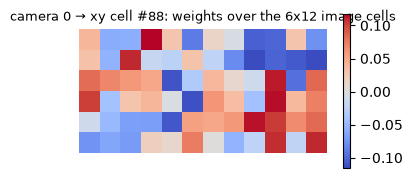

In [8]:
h, w = features[lifter.level].shape[-2:]
cell = 5 * scene.grid.resolution[1] + 8
W = lifter.view_mlps[0][0].weight[cell].detach().view(h, w)
plt.figure(figsize=(4, 2), facecolor="white"); plt.imshow(W, cmap="coolwarm"); plt.colorbar()
plt.title(f"camera 0 → xy cell #{cell}: weights over the {h}x{w} image cells", fontsize=9); plt.axis("off"); plt.show()

## 6. The triplane contract, verified

Every triplane lifter promises the same five properties (Liskov: it is still a `BaseLifter`, so it drops into
`BEVSegmentationModel`, the trainer and the verifier unchanged). `TriplaneContractChecker` runs them on real tensors.

PASS  plane shapes            xy(4, 32, 16, 16) xz(4, 32, 16, 4) yz(4, 32, 16, 4)
PASS  BEV = bev_head(planes)  BEV (4, 32, 16, 16), max |diff| = 0.0e+00
PASS  f = xy + xz + yz        voxel (8,8,2) max |diff| = 0.0e+00
PASS  reuses BEV lifter       native triplane lifter built from existing layers (MLPViewTriplaneLifter)
PASS  gradients reach images  1/2 pyramid levels receive gradient


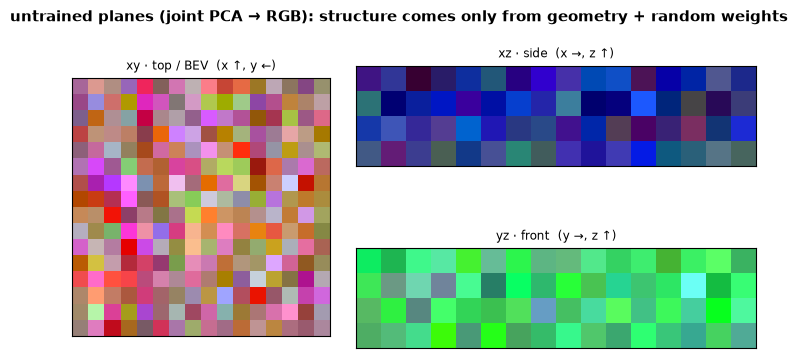

In [9]:
assert TriplaneContractChecker(lifter, features, cameras).run()
with torch.no_grad():
    planes = lifter.lift_planes(features, cameras)
plotter.features(planes, title="untrained planes (joint PCA → RGB): structure comes only from geometry + random weights")

## 7. Train end to end on 3D semantic occupancy

`build_triplane_model("mlp_view", ...)` = encoder → **this triplane lifter** → `TPVAggregator` (an MLP on
`f(x,y,z) = xy + xz + yz`), plus one auxiliary classifier per plane. `OccupancyTask(aux_weight=0.5)` adds a
cross-entropy on each plane against the collapsed labels of §3. 150 AdamW steps on 128 scenes, CPU only.

lifter          params    time   before    after  corrupted   verdict
mlp_view          318k    3.4s    0.013    0.038      0.038   cannot localise objects


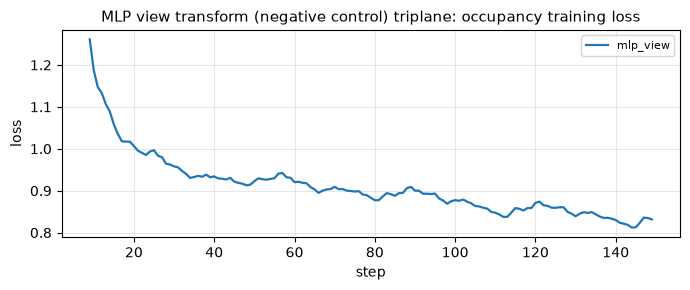

In [10]:
exp = OccupancyExperiment(scene, "mlp_view")
result = exp.run(steps=150)
print(ExperimentResult.header()); print(result.row())
OccupancyExperiment.plot_losses([result], title="MLP view transform (negative control) triplane: occupancy training loss")

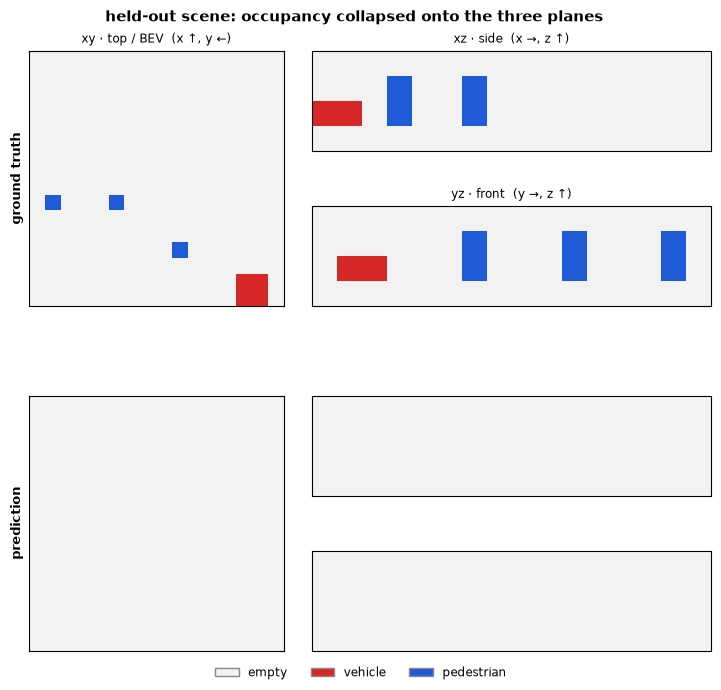

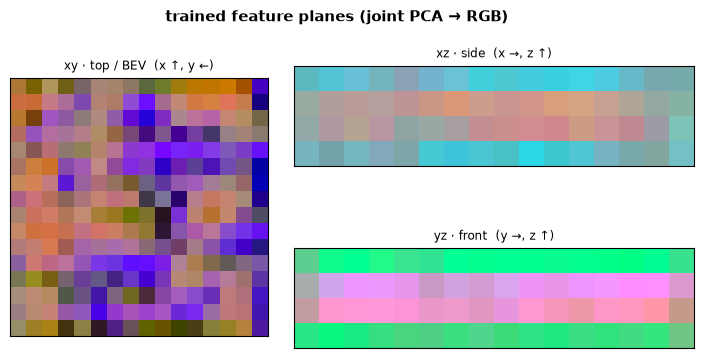

In [11]:
out = exp.predict()
pred = out["voxel_logits"].argmax(1)                       # (B, X, Y, Z) class ids
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("prediction", scene.label_planes(pred))],
               title="held-out scene: occupancy collapsed onto the three planes")
plotter.features(out["planes"], title="trained feature planes (joint PCA → RGB)")

### The control vs a geometric triplane lifter

Train `simple_bev` (parameter-free geometry) with the same budget: the gap is what geometry buys.

lifter          params    time   before    after  corrupted   verdict
mlp_view          318k    3.4s    0.013    0.038      0.038   cannot localise objects
simple_bev        510k    5.1s    0.000    0.375      0.030   uses geometry


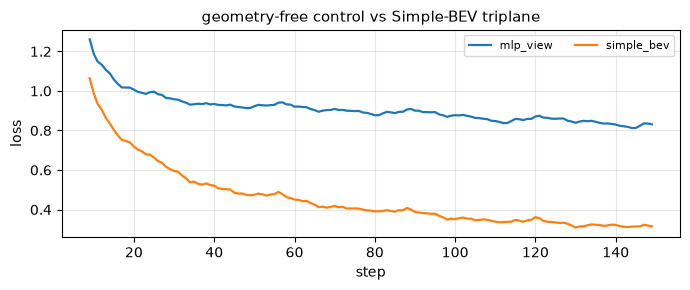

In [12]:
result_geo = OccupancyExperiment(scene, "simple_bev").run(steps=150)
print(ExperimentResult.header()); print(result.row()); print(result_geo.row())
OccupancyExperiment.plot_losses([result, result_geo], title="geometry-free control vs Simple-BEV triplane")

## 8. Negative control: does it really use the cameras?

Same images, same weights - but every camera's extrinsic is rotated by 90° about the vertical axis. A lifter that reads
pixels **through** the calibration now puts every object in the wrong place and its mIoU collapses; a geometry-free
lifter would not notice. (This is the triplane version of the repo's `lifting-verify` check.)

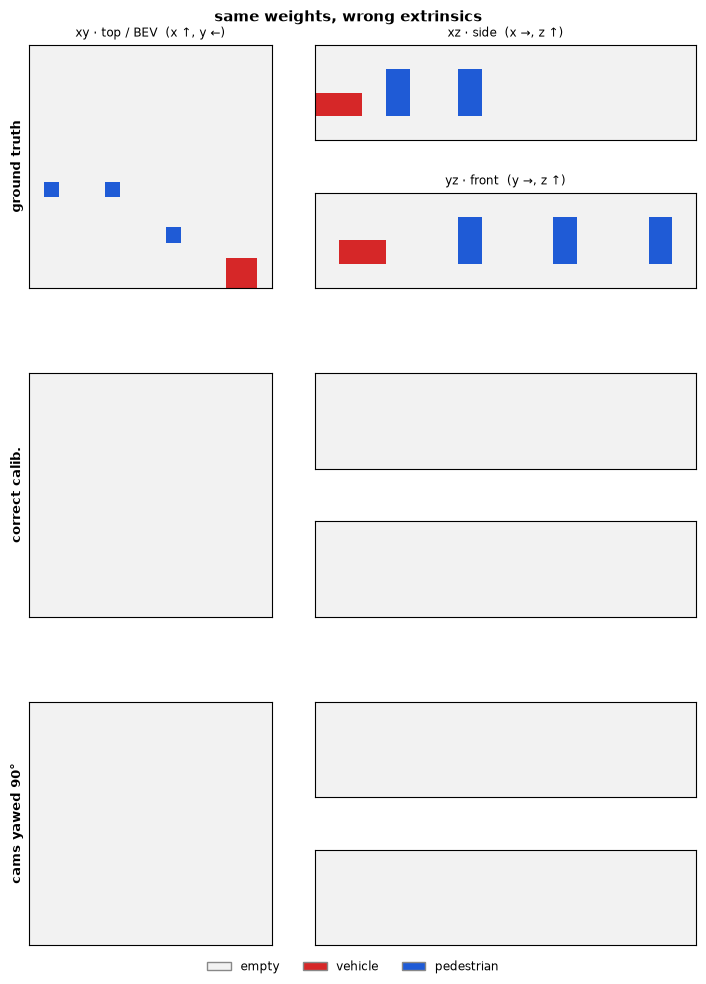

mIoU  correct calibration: 0.038   |   cameras yawed 90°: 0.038   ->  does NOT use geometry


In [13]:
corrupted = exp.predict(corrupted=True)["voxel_logits"].argmax(1)
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("correct calib.", scene.label_planes(pred)),
                ("cams yawed 90°", scene.label_planes(corrupted))],
               title="same weights, wrong extrinsics")
print(f"mIoU  correct calibration: {result.miou_after:.3f}   |   cameras yawed 90°: {result.miou_corrupted:.3f}"
      f"   ->  {'uses geometry ✅' if result.uses_geometry else 'does NOT use geometry'}")

## 9. Use it in your own code

```python
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_model, build_triplane_bev_model

# 1) just the lifter: features (B, N, C, H_l, W_l) per level + Cameras
lifter = TRIPLANE_LIFTERS.build("mlp_view", grid=grid, in_channels=64, out_channels=64)
planes = lifter.lift_planes(features, cameras)   # TPVPlanes(xy, xz, yz)
bev    = lifter(features, cameras)               # (B, 64, X, Y) - drop-in BEV lifter

# 2) 3D semantic occupancy + point queries
model = build_triplane_model("mlp_view", grid, num_classes=3, aux_heads=True)
out = model(images, cameras, points=lidar_xyz)   # planes, voxel_logits, point_logits, aux_logits

# 3) BEV segmentation read off the triplane (same API as lifting.build_bev_model)
bev_model = build_triplane_bev_model("mlp_view", grid, num_classes=3)
```

In [14]:
bev_model = build_triplane_bev_model("mlp_view", scene.grid, 3, scene.image_size, scene.num_cameras, channels=16)
with torch.no_grad():
    logits = bev_model(batch.images, batch.cameras)["logits"]
print("BEV segmentation logits read off the triplane:", tuple(logits.shape))

BEV segmentation logits read off the triplane: (4, 3, 16, 16)


## Recap


* The MLP view triplane maps image cells to plane cells with learned dense layers - no calibration.
* Its planes are identical under any change of extrinsics; with randomly rotated rigs it cannot localise objects.
* Use it as the floor every geometric triplane lifter must beat (`ExperimentResult.verdict`).


**Cheat sheet**

| concept | file |
|---|---|
| BEV version (unchanged) | `src/lifting/lifters/mlp_view_lifter.py` |
| triplane version | `src/lifting/triplane/mlp_view_triplane.py` |
| extrinsic corruption | `src/lifting/verification/extrinsic_corruption.py` |
| triplane contract | `src/lifting/triplane/base.py` |
| BEV read-off from planes | `src/lifting/triplane/triplane_bev_head.py` |
| occupancy model / factories | `src/lifting/triplane/triplane_occupancy_model.py`, `factory.py` |
| this animation | `src/lifting/triplane/animation/storyboards/mlp_view_storyboard.py` |

**Exercises**

1. Train on a fixed rig (`CameraRig(yaw_jitter_deg=0)`). How close does the control get to `simple_bev` now?
2. Count parameters as a function of grid resolution - why does VPN not scale to 200×200×16?

Next: see `00_triplane_overview.ipynb` for all techniques side by side.